In [1]:

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload dataset
uploaded = files.upload()

# Load CSV file
filename = list(uploaded.keys())[0]
data = pd.read_csv(filename)

# Display dataset details
print("DATASET LOADED SUCCESSFULLY!")
print("Dataset shape:", data.shape)

print("\nFirst 5 rows:")
display(data.head())


Saving Toronto Island Ferry Tickets.csv to Toronto Island Ferry Tickets.csv
DATASET LOADED SUCCESSFULLY!
Dataset shape: (261538, 4)

First 5 rows:


,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21T22:30:00,14,16
1,2,2025-12-21T22:15:00,1,0
2,3,2025-12-21T22:00:00,2,0
3,4,2025-12-21T21:30:00,11,1
4,5,2025-12-21T21:15:00,10,0


In [2]:

# STEP 2: DATASET EXPLORATION

# Dataset dimensions
print("Dataset Shape:", data.shape)

# Column names
print("\nColumn Names:")
print(data.columns.tolist())

# Data types
print("\nData Types:")
print(data.dtypes)

# Statistical summary
print("\nStatistical Summary:")
display(data.describe())

# First 10 records
print("\nFirst 10 Records:")
display(data.head(10))

# Last 5 records
print("\nLast 5 Records:")
display(data.tail())


Dataset Shape: (261538, 4)

Column Names:
['_id', 'Timestamp', 'Redemption Count', 'Sales Count']

Data Types:
_id                  int64
Timestamp           object
Redemption Count     int64
Sales Count          int64
dtype: object

Statistical Summary:


,_id,Redemption Count,Sales Count
count,261538.000000,261538.000000,261538.000000
mean,130769.500000,48.885030,49.599106
std,75499.661689,104.549336,99.862285
min,1.000000,0.000000,0.000000
25%,65385.250000,3.000000,3.000000
50%,130769.500000,11.000000,13.000000
75%,196153.750000,40.000000,48.000000
max,261538.000000,7216.000000,7229.000000



First 10 Records:


,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21T22:30:00,14,16
1,2,2025-12-21T22:15:00,1,0
2,3,2025-12-21T22:00:00,2,0
3,4,2025-12-21T21:30:00,11,1
4,5,2025-12-21T21:15:00,10,0
5,6,2025-12-21T21:00:00,3,0
6,7,2025-12-21T20:30:00,17,10
7,8,2025-12-21T20:15:00,3,1
8,9,2025-12-21T20:00:00,0,2
9,10,2025-12-21T19:30:00,6,1



Last 5 Records:


,_id,Timestamp,Redemption Count,Sales Count
261533,261534,2015-05-04T16:00:00,0,2
261534,261535,2015-05-01T16:00:00,1,0
261535,261536,2015-05-01T15:45:00,0,1
261536,261537,2015-05-01T15:15:00,0,2
261537,261538,2015-05-01T13:30:00,0,1


In [3]:
print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nData Types:")
print(data.dtypes)

print("\nStatistical Summary:")
display(data.describe())

print("\nFirst 10 Records:")
display(data.head(10))

print("\nLast 5 Records:")
display(data.tail())

Dataset Shape: (261538, 4)

Column Names:
['_id', 'Timestamp', 'Redemption Count', 'Sales Count']

Data Types:
_id                  int64
Timestamp           object
Redemption Count     int64
Sales Count          int64
dtype: object

Statistical Summary:


,_id,Redemption Count,Sales Count
count,261538.000000,261538.000000,261538.000000
mean,130769.500000,48.885030,49.599106
std,75499.661689,104.549336,99.862285
min,1.000000,0.000000,0.000000
25%,65385.250000,3.000000,3.000000
50%,130769.500000,11.000000,13.000000
75%,196153.750000,40.000000,48.000000
max,261538.000000,7216.000000,7229.000000



First 10 Records:


,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21T22:30:00,14,16
1,2,2025-12-21T22:15:00,1,0
2,3,2025-12-21T22:00:00,2,0
3,4,2025-12-21T21:30:00,11,1
4,5,2025-12-21T21:15:00,10,0
5,6,2025-12-21T21:00:00,3,0
6,7,2025-12-21T20:30:00,17,10
7,8,2025-12-21T20:15:00,3,1
8,9,2025-12-21T20:00:00,0,2
9,10,2025-12-21T19:30:00,6,1



Last 5 Records:


,_id,Timestamp,Redemption Count,Sales Count
261533,261534,2015-05-04T16:00:00,0,2
261534,261535,2015-05-01T16:00:00,1,0
261535,261536,2015-05-01T15:45:00,0,1
261536,261537,2015-05-01T15:15:00,0,2
261537,261538,2015-05-01T13:30:00,0,1


In [4]:
# Create a working copy of the dataset
clean_data = data.copy()

# 1. Check missing values
print("Missing Values:")
print(clean_data.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:")
print(clean_data.duplicated().sum())

# 3. Remove exact duplicate rows
clean_data = clean_data.drop_duplicates()

# 4. Convert Timestamp into datetime format
clean_data["Timestamp"] = pd.to_datetime(
    clean_data["Timestamp"], errors="coerce"
)

# 5. Convert ticket counts into numeric format
clean_data["Sales Count"] = pd.to_numeric(
    clean_data["Sales Count"], errors="coerce"
)

clean_data["Redemption Count"] = pd.to_numeric(
    clean_data["Redemption Count"], errors="coerce"
)

# 6. Check invalid values after conversion
print("\nInvalid Timestamps:",
      clean_data["Timestamp"].isna().sum())

print("Missing Sales Count:",
      clean_data["Sales Count"].isna().sum())

print("Missing Redemption Count:",
      clean_data["Redemption Count"].isna().sum())

# 7. Display cleaned dataset information
print("\nCleaned Dataset Shape:", clean_data.shape)
print("\nUpdated Data Types:")
print(clean_data.dtypes)

display(clean_data.head())

Missing Values:
_id                 0
Timestamp           0
Redemption Count    0
Sales Count         0
dtype: int64

Duplicate Records:
0

Invalid Timestamps: 0
Missing Sales Count: 0
Missing Redemption Count: 0

Cleaned Dataset Shape: (261538, 4)

Updated Data Types:
_id                          int64
Timestamp           datetime64[ns]
Redemption Count             int64
Sales Count                  int64
dtype: object


,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21 22:30:00,14,16
1,2,2025-12-21 22:15:00,1,0
2,3,2025-12-21 22:00:00,2,0
3,4,2025-12-21 21:30:00,11,1
4,5,2025-12-21 21:15:00,10,0


In [5]:
# Extract date and time features

clean_data["Date"] = clean_data["Timestamp"].dt.date
clean_data["Hour"] = clean_data["Timestamp"].dt.hour
clean_data["Day"] = clean_data["Timestamp"].dt.day
clean_data["Month"] = clean_data["Timestamp"].dt.month
clean_data["Month_Name"] = clean_data["Timestamp"].dt.month_name()
clean_data["Year"] = clean_data["Timestamp"].dt.year
clean_data["Day_Name"] = clean_data["Timestamp"].dt.day_name()

# Classify weekdays and weekends
clean_data["Day_Type"] = clean_data["Timestamp"].dt.dayofweek.map(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

# Display the updated dataset
print("Updated Dataset:")
display(clean_data.head(10))

print("\nNew Column Names:")
print(clean_data.columns.tolist())

print("\nUpdated Dataset Shape:")
print(clean_data.shape)

Updated Dataset:


,_id,Timestamp,Redemption Count,Sales Count,Date,Hour,Day,Month,Month_Name,Year,Day_Name,Day_Type
0,1,2025-12-21 22:30:00,14,16,2025-12-21,22,21,12,December,2025,Sunday,Weekend
1,2,2025-12-21 22:15:00,1,0,2025-12-21,22,21,12,December,2025,Sunday,Weekend
2,3,2025-12-21 22:00:00,2,0,2025-12-21,22,21,12,December,2025,Sunday,Weekend
3,4,2025-12-21 21:30:00,11,1,2025-12-21,21,21,12,December,2025,Sunday,Weekend
4,5,2025-12-21 21:15:00,10,0,2025-12-21,21,21,12,December,2025,Sunday,Weekend
5,6,2025-12-21 21:00:00,3,0,2025-12-21,21,21,12,December,2025,Sunday,Weekend
6,7,2025-12-21 20:30:00,17,10,2025-12-21,20,21,12,December,2025,Sunday,Weekend
7,8,2025-12-21 20:15:00,3,1,2025-12-21,20,21,12,December,2025,Sunday,Weekend
8,9,2025-12-21 20:00:00,0,2,2025-12-21,20,21,12,December,2025,Sunday,Weekend
9,10,2025-12-21 19:30:00,6,1,2025-12-21,19,21,12,December,2025,Sunday,Weekend



New Column Names:
['_id', 'Timestamp', 'Redemption Count', 'Sales Count', 'Date', 'Hour', 'Day', 'Month', 'Month_Name', 'Year', 'Day_Name', 'Day_Type']

Updated Dataset Shape:
(261538, 12)


In [6]:
# Basic dataset statistics

print("TOTAL SALES:", clean_data["Sales Count"].sum())

print("TOTAL REDEMPTIONS:",
      clean_data["Redemption Count"].sum())

print("\nAVERAGE SALES:",
      clean_data["Sales Count"].mean())

print("AVERAGE REDEMPTIONS:",
      clean_data["Redemption Count"].mean())

print("\nMAXIMUM SALES:",
      clean_data["Sales Count"].max())

print("MAXIMUM REDEMPTIONS:",
      clean_data["Redemption Count"].max())

print("\nMINIMUM SALES:",
      clean_data["Sales Count"].min())

print("MINIMUM REDEMPTIONS:",
      clean_data["Redemption Count"].min())

# Daily sales and redemption summary
daily_summary = clean_data.groupby("Date")[
    ["Sales Count", "Redemption Count"]
].sum()

print("\nDAILY SUMMARY:")
display(daily_summary.head(10))

TOTAL SALES: 12972051
TOTAL REDEMPTIONS: 12785293

AVERAGE SALES: 49.59910605724598
AVERAGE REDEMPTIONS: 48.885030091229574

MAXIMUM SALES: 7229
MAXIMUM REDEMPTIONS: 7216

MINIMUM SALES: 0
MINIMUM REDEMPTIONS: 0

DAILY SUMMARY:


,Sales Count,Redemption Count
Date,,
2015-05-01,4,1
2015-05-04,75,12
2015-05-05,549,537
2015-05-06,1358,989
2015-05-07,2170,1343
2015-05-08,3390,2108
2015-05-09,6145,5604
2015-05-10,3554,3013
2015-05-11,908,395


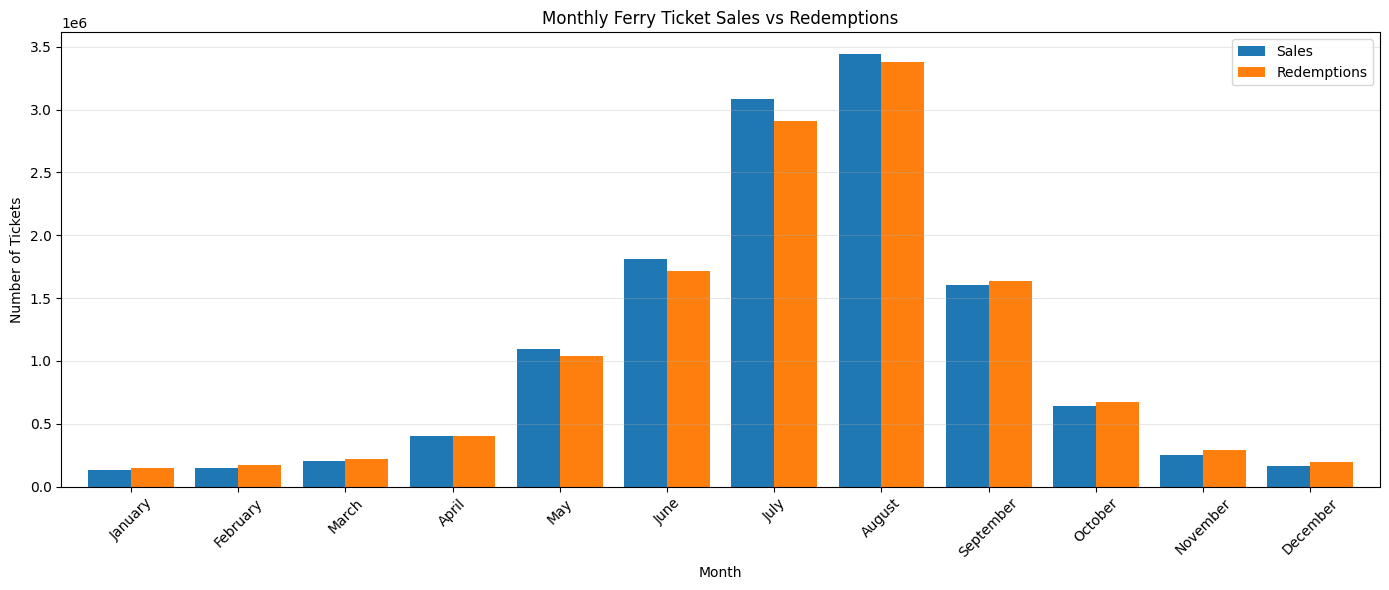

In [7]:
# Group data by month
monthly_summary = clean_data.groupby("Month_Name")[
    ["Sales Count", "Redemption Count"]
].sum()

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_summary = monthly_summary.reindex(month_order)

# Plot monthly sales and redemptions
monthly_summary.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Monthly Ferry Ticket Sales vs Redemptions")
plt.xlabel("Month")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.legend(["Sales", "Redemptions"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

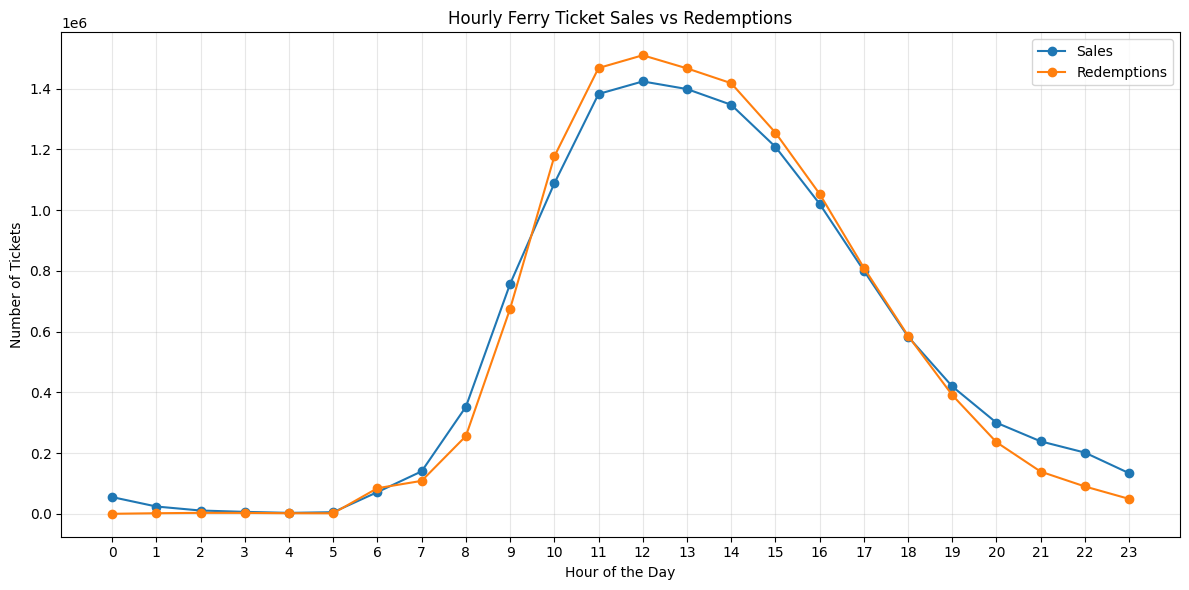

In [8]:
# Group ticket sales by hour
hourly_summary = clean_data.groupby("Hour")[
    ["Sales Count", "Redemption Count"]
].sum()

# Create hourly chart
hourly_summary.plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Hourly Ferry Ticket Sales vs Redemptions")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Tickets")
plt.xticks(range(0, 24))
plt.legend(["Sales", "Redemptions"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Weekday vs Weekend Summary:


,Sales Count,Redemption Count
Day_Type,,
Weekday,7693663,7308559
Weekend,5278388,5476734


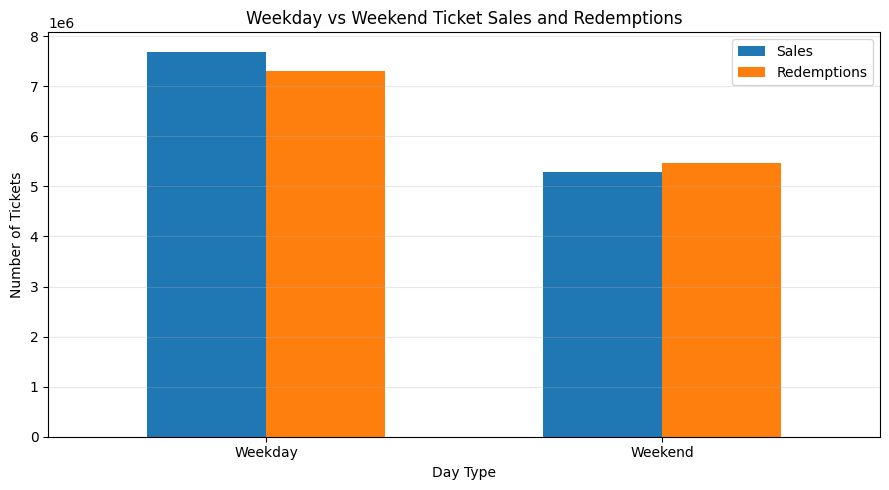

In [9]:
# Group data by day type
day_summary = clean_data.groupby("Day_Type")[
    ["Sales Count", "Redemption Count"]
].sum()

print("Weekday vs Weekend Summary:")
display(day_summary)

# Create comparison chart
day_summary.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.6
)

plt.title("Weekday vs Weekend Ticket Sales and Redemptions")
plt.xlabel("Day Type")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.legend(["Sales", "Redemptions"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Year-wise Sales and Redemption Summary:


,Sales Count,Redemption Count
Year,,
2015,1189620,978707
2016,1518428,1425779
2017,682346,698861
2018,1463589,1493560
2019,1249725,1278505
2020,366606,374546
2021,782368,773040
2022,1346659,1349778
2023,1491473,1502883


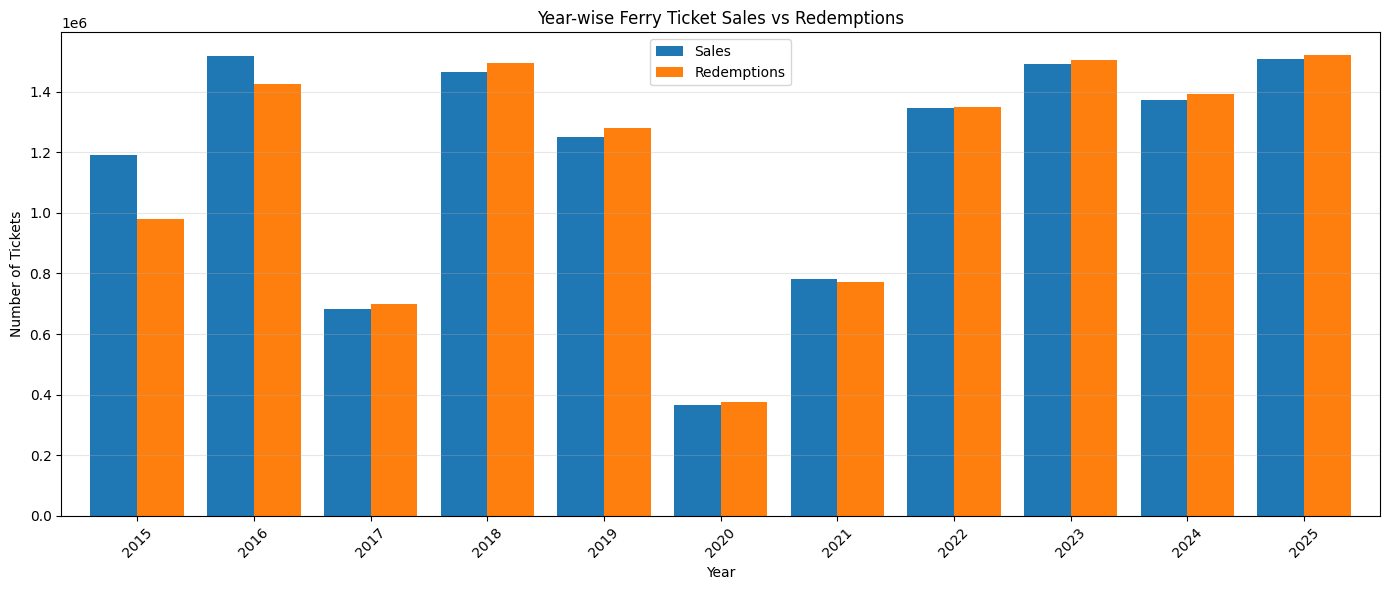

In [10]:
# Group data by year
yearly_summary = clean_data.groupby("Year")[
    ["Sales Count", "Redemption Count"]
].sum()

print("Year-wise Sales and Redemption Summary:")
display(yearly_summary)

# Create comparison chart
yearly_summary.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Year-wise Ferry Ticket Sales vs Redemptions")
plt.xlabel("Year")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.legend(["Sales", "Redemptions"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Total Tickets Sold: 12972051
Total Tickets Redeemed: 12785293

Overall Redemption Rate: 98.56 %

Year-wise Redemption Rate:


,Sales Count,Redemption Count,Redemption Rate (%)
Year,,,
2015,1189620,978707,82.270557
2016,1518428,1425779,93.898361
2017,682346,698861,102.420326
2018,1463589,1493560,102.047774
2019,1249725,1278505,102.302907
2020,366606,374546,102.165813
2021,782368,773040,98.807722
2022,1346659,1349778,100.231610
2023,1491473,1502883,100.765016


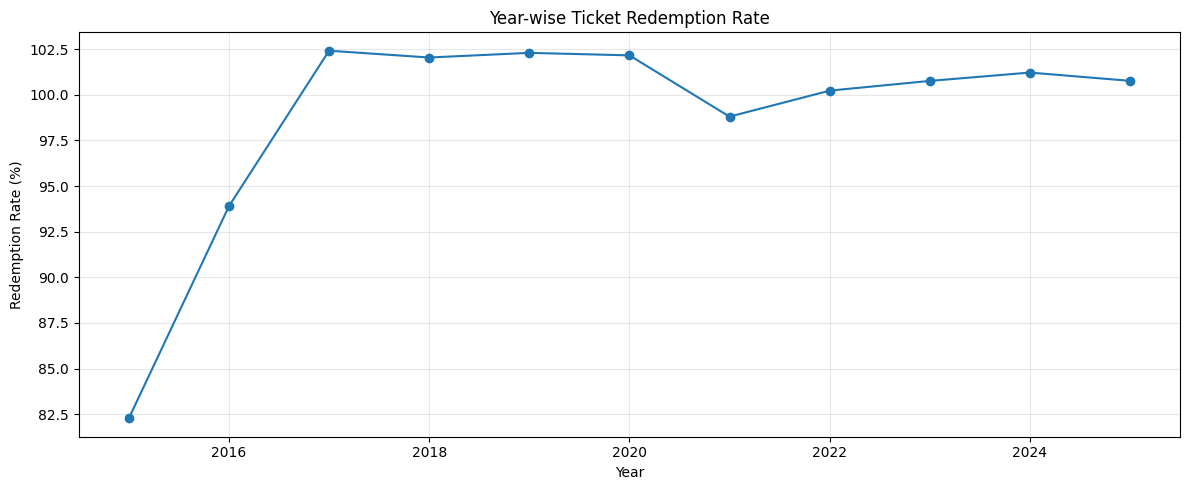

In [11]:
# Calculate total sales and redemptions
total_sales = clean_data["Sales Count"].sum()
total_redemptions = clean_data["Redemption Count"].sum()

# Calculate overall redemption rate
redemption_rate = (total_redemptions / total_sales) * 100

print("Total Tickets Sold:", total_sales)
print("Total Tickets Redeemed:", total_redemptions)

print("\nOverall Redemption Rate:",
      round(redemption_rate, 2), "%")

# Calculate redemption rate by year
yearly_rate = clean_data.groupby("Year").agg({
    "Sales Count": "sum",
    "Redemption Count": "sum"
})

yearly_rate["Redemption Rate (%)"] = (
    yearly_rate["Redemption Count"] /
    yearly_rate["Sales Count"] * 100
)

print("\nYear-wise Redemption Rate:")
display(yearly_rate)

# Plot yearly redemption rate
yearly_rate["Redemption Rate (%)"].plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Year-wise Ticket Redemption Rate")
plt.xlabel("Year")
plt.ylabel("Redemption Rate (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

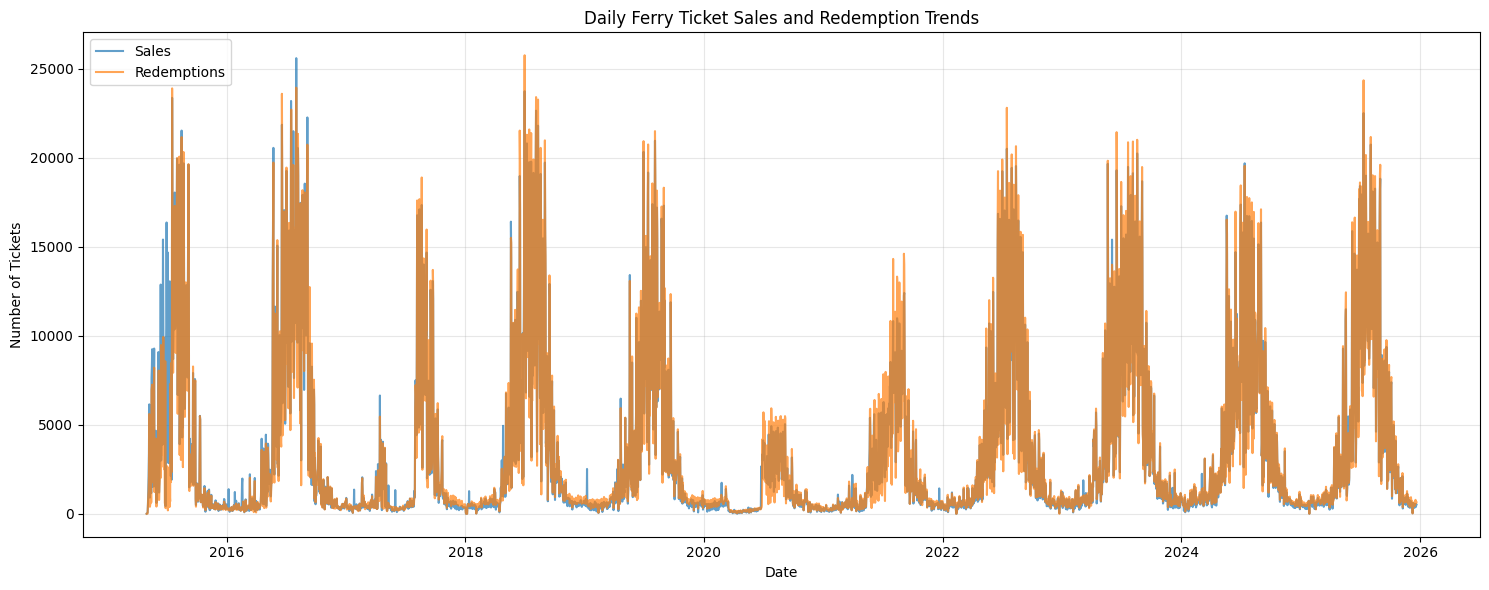

In [12]:
# Group ticket activity by date
daily_trend = clean_data.groupby("Date")[
    ["Sales Count", "Redemption Count"]
].sum()

# Convert index to datetime
daily_trend.index = pd.to_datetime(daily_trend.index)

# Plot daily trends
plt.figure(figsize=(15, 6))

plt.plot(
    daily_trend.index,
    daily_trend["Sales Count"],
    label="Sales",
    alpha=0.7
)

plt.plot(
    daily_trend.index,
    daily_trend["Redemption Count"],
    label="Redemptions",
    alpha=0.7
)

plt.title("Daily Ferry Ticket Sales and Redemption Trends")
plt.xlabel("Date")
plt.ylabel("Number of Tickets")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

TOP 10 DAYS WITH HIGHEST TICKET SALES:


,Sales Count,Redemption Count
Date,,
2016-08-01,25585,23928
2018-07-01,23729,25748
2015-07-18,23354,23889
2016-07-16,23181,22690
2018-08-05,22634,23399
2025-07-12,22500,24341
2016-09-04,22256,20729
2016-06-18,21844,23584
2018-08-11,21792,23260



TOP 10 DAYS WITH HIGHEST REDEMPTIONS:


,Sales Count,Redemption Count
Date,,
2018-07-01,23729,25748
2025-07-12,22500,24341
2016-08-01,25585,23928
2015-07-18,23354,23889
2016-06-18,21844,23584
2018-08-05,22634,23399
2018-08-11,21792,23260
2022-07-16,20498,22798
2016-07-17,20661,22694


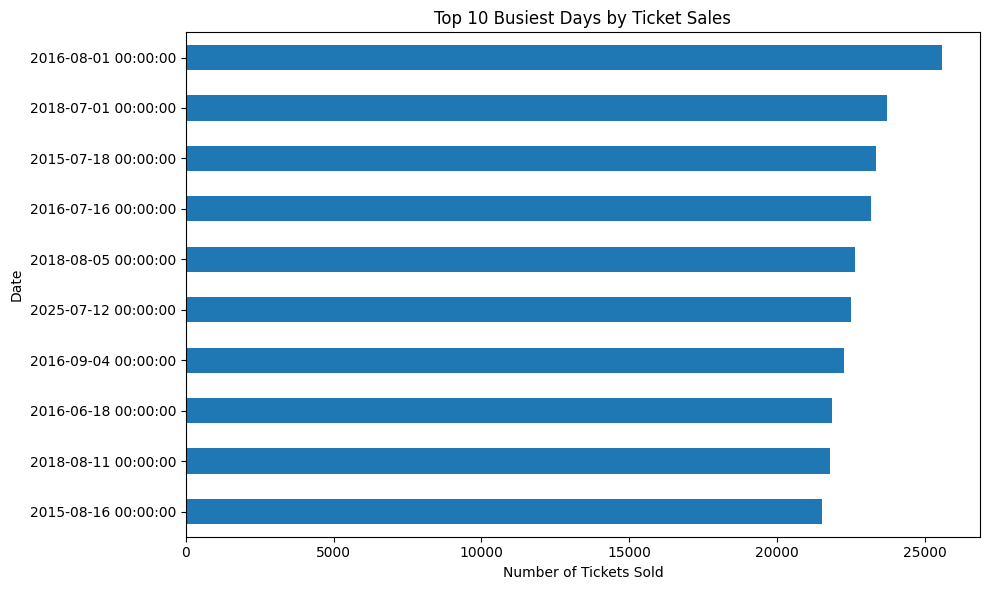

In [13]:
# Find the top 10 busiest days by sales
top_sales_days = daily_trend.sort_values(
    by="Sales Count",
    ascending=False
).head(10)

print("TOP 10 DAYS WITH HIGHEST TICKET SALES:")
display(top_sales_days)

# Find the top 10 busiest days by redemptions
top_redemption_days = daily_trend.sort_values(
    by="Redemption Count",
    ascending=False
).head(10)

print("\nTOP 10 DAYS WITH HIGHEST REDEMPTIONS:")
display(top_redemption_days)

# Visualize the busiest sales days
top_sales_days["Sales Count"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Busiest Days by Ticket Sales")
plt.xlabel("Number of Tickets Sold")
plt.ylabel("Date")
plt.tight_layout()
plt.show()

Sales and Redemption Correlation:


,Sales Count,Redemption Count
Sales Count,1.000000,0.918163
Redemption Count,0.918163,1.000000



Correlation Value: 0.918


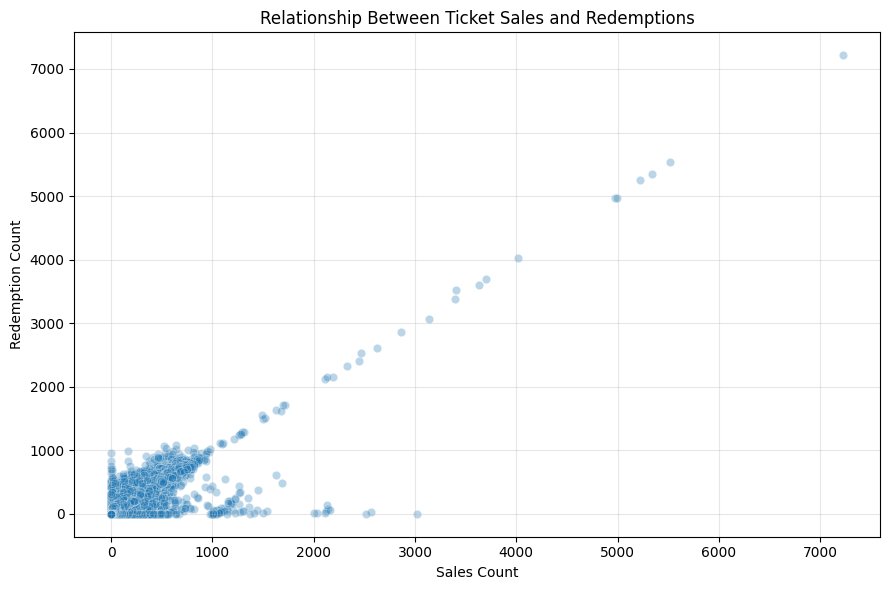

In [14]:
# Calculate correlation
correlation = clean_data[
    ["Sales Count", "Redemption Count"]
].corr()

print("Sales and Redemption Correlation:")
display(correlation)

print(
    "\nCorrelation Value:",
    round(correlation.loc["Sales Count", "Redemption Count"], 3)
)

# Create scatter plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=clean_data,
    x="Sales Count",
    y="Redemption Count",
    alpha=0.3
)

plt.title("Relationship Between Ticket Sales and Redemptions")
plt.xlabel("Sales Count")
plt.ylabel("Redemption Count")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Calculate IQR for Sales Count
Q1_sales = clean_data["Sales Count"].quantile(0.25)
Q3_sales = clean_data["Sales Count"].quantile(0.75)
IQR_sales = Q3_sales - Q1_sales

upper_sales = Q3_sales + 1.5 * IQR_sales

# Calculate IQR for Redemption Count
Q1_redemption = clean_data["Redemption Count"].quantile(0.25)
Q3_redemption = clean_data["Redemption Count"].quantile(0.75)
IQR_redemption = Q3_redemption - Q1_redemption

upper_redemption = Q3_redemption + 1.5 * IQR_redemption

# Count outliers
sales_outliers = clean_data[
    clean_data["Sales Count"] > upper_sales
]

redemption_outliers = clean_data[
    clean_data["Redemption Count"] > upper_redemption
]

print("Sales Outlier Threshold:", upper_sales)
print("Number of Sales Outliers:", len(sales_outliers))

print("\nRedemption Outlier Threshold:", upper_redemption)
print("Number of Redemption Outliers:", len(redemption_outliers))

print("\nTop 10 Sales Outliers:")
display(
    sales_outliers.sort_values(
        "Sales Count", ascending=False
    ).head(10)
)

print("\nTop 10 Redemption Outliers:")
display(
    redemption_outliers.sort_values(
        "Redemption Count", ascending=False
    ).head(10)
)

Sales Outlier Threshold: 115.5
Number of Sales Outliers: 32626

Redemption Outlier Threshold: 95.5
Number of Redemption Outliers: 36857

Top 10 Sales Outliers:


,_id,Timestamp,Redemption Count,Sales Count,Date,Hour,Day,Month,Month_Name,Year,Day_Name,Day_Type
61624,61625,2023-08-15 20:15:00,7216,7229,2023-08-15,20,15,8,August,2023,Tuesday,Weekday
57273,57274,2023-10-10 14:00:00,5535,5518,2023-10-10,14,10,10,October,2023,Tuesday,Weekday
40147,40148,2024-06-19 19:00:00,5341,5342,2024-06-19,19,19,6,June,2024,Wednesday,Weekday
7768,7769,2025-09-01 17:30:00,5256,5218,2025-09-01,17,1,9,September,2025,Monday,Weekday
36211,36212,2024-08-05 22:00:00,4973,4995,2024-08-05,22,5,8,August,2024,Monday,Weekday
33540,33541,2024-09-07 17:00:00,4966,4974,2024-09-07,17,7,9,September,2024,Saturday,Weekend
5965,5966,2025-09-24 22:30:00,4020,4015,2025-09-24,22,24,9,September,2025,Wednesday,Weekday
11651,11652,2025-07-17 23:15:00,3692,3701,2025-07-17,23,17,7,July,2025,Thursday,Weekday
65040,65041,2023-07-05 21:15:00,3602,3634,2023-07-05,21,5,7,July,2023,Wednesday,Weekday
87888,87889,2022-08-15 10:30:00,3520,3408,2022-08-15,10,15,8,August,2022,Monday,Weekday



Top 10 Redemption Outliers:


,_id,Timestamp,Redemption Count,Sales Count,Date,Hour,Day,Month,Month_Name,Year,Day_Name,Day_Type
61624,61625,2023-08-15 20:15:00,7216,7229,2023-08-15,20,15,8,August,2023,Tuesday,Weekday
57273,57274,2023-10-10 14:00:00,5535,5518,2023-10-10,14,10,10,October,2023,Tuesday,Weekday
40147,40148,2024-06-19 19:00:00,5341,5342,2024-06-19,19,19,6,June,2024,Wednesday,Weekday
7768,7769,2025-09-01 17:30:00,5256,5218,2025-09-01,17,1,9,September,2025,Monday,Weekday
36211,36212,2024-08-05 22:00:00,4973,4995,2024-08-05,22,5,8,August,2024,Monday,Weekday
33540,33541,2024-09-07 17:00:00,4966,4974,2024-09-07,17,7,9,September,2024,Saturday,Weekend
5965,5966,2025-09-24 22:30:00,4020,4015,2025-09-24,22,24,9,September,2025,Wednesday,Weekday
11651,11652,2025-07-17 23:15:00,3692,3701,2025-07-17,23,17,7,July,2025,Thursday,Weekday
65040,65041,2023-07-05 21:15:00,3602,3634,2023-07-05,21,5,7,July,2023,Wednesday,Weekday
87888,87889,2022-08-15 10:30:00,3520,3408,2022-08-15,10,15,8,August,2022,Monday,Weekday


In [16]:
# Sort records by timestamp
time_data = clean_data.sort_values("Timestamp").copy()

# Calculate time difference between consecutive records
time_data["Time_Gap"] = time_data["Timestamp"].diff()

# Display most common time intervals
print("Most Common Timestamp Intervals:")
display(
    time_data["Time_Gap"].value_counts().head(10)
)

# Find large gaps (more than 1 hour)
large_gaps = time_data[
    time_data["Time_Gap"] > pd.Timedelta(hours=1)
]

print("\nNumber of Gaps Greater Than 1 Hour:")
print(len(large_gaps))

print("\nLargest 10 Time Gaps:")
display(
    time_data.nlargest(10, "Time_Gap")[
        ["Timestamp", "Time_Gap"]
    ]
)

Most Common Timestamp Intervals:


,count
Time_Gap,
0 days 00:15:00,236262
0 days 00:30:00,13415
0 days 00:45:00,4407
0 days 01:00:00,1834
0 days 01:15:00,782
0 days 01:30:00,526
0 days 07:00:00,469
0 days 01:45:00,363
0 days 02:00:00,304



Number of Gaps Greater Than 1 Hour:
5619

Largest 10 Time Gaps:


,Timestamp,Time_Gap
261533,2015-05-04 16:00:00,3 days 00:00:00
126418,2021-02-23 16:00:00,2 days 22:00:00
24062,2025-01-27 10:30:00,1 days 11:00:00
201144,2018-01-05 06:45:00,1 days 07:15:00
201147,2018-01-03 12:15:00,1 days 04:45:00
201143,2018-01-06 11:15:00,1 days 04:30:00
199547,2018-02-04 07:45:00,0 days 20:30:00
769,2025-12-09 11:45:00,0 days 20:00:00
174043,2019-02-13 06:15:00,0 days 19:15:00
201139,2018-01-07 07:45:00,0 days 17:15:00


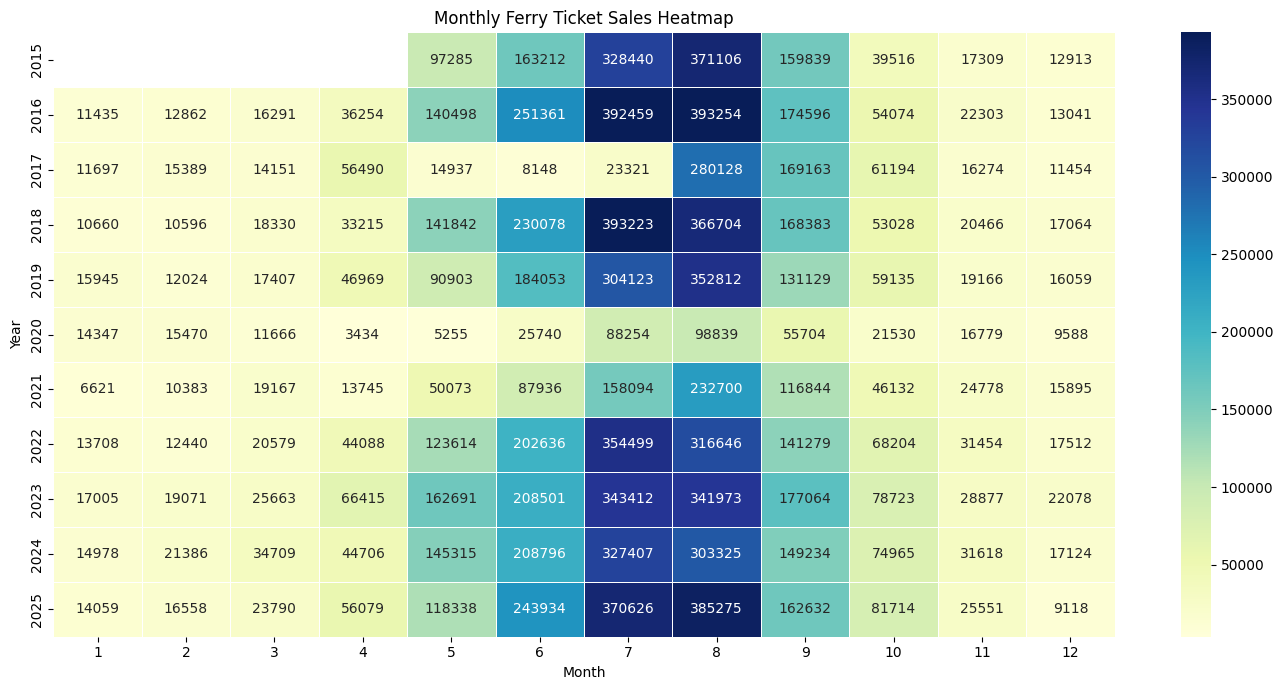

In [17]:
# Group ticket sales by year and month
heatmap_data = clean_data.pivot_table(
    index="Year",
    columns="Month",
    values="Sales Count",
    aggfunc="sum"
)

# Create heatmap
plt.figure(figsize=(14, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Monthly Ferry Ticket Sales Heatmap")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

In [18]:
# Save cleaned dataset
clean_data.to_csv(
    "Toronto_Ferry_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

# Download the cleaned CSV file
from google.colab import files
files.download("Toronto_Ferry_Cleaned.csv")

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>